# Aula 09 — Qualidade de Dados e Limpeza (Teórico-Prática) · Conteúdo

**Unidade 2 — Aquisição e Preparação de Dados** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

**🧹 Aula 09 — Qualidade de Dados e Limpeza (Teórico-Prática)**

Quarta aula da Unidade 2 (Aquisição e Preparação de Dados). Valores ausentes (`isna`, `fillna`, `dropna`); detecção de outliers (IQR, z-score); duplicatas; normalização e padronização; conceitos de tidy data. Prática com **dados sintéticos da área da saúde** — atendimentos em UBS do RN e triagem de pronto atendimento —, com problemas de qualidade inseridos de propósito (nenhum dado é de paciente real). Recursos: Jupyter Notebook, datasets sujos. Avaliação: formulário avaliativo com 10 questões — prazo de envio até 30/10/2026. O exercício prático é para treino e **não precisa ser entregue**. Materiais desta aula: livro Tópicos de Estudo (5 capítulos) · apostila completa em PDF · pacote com notebooks e datasets · formulário avaliativo.

---
## Tópicos de Estudo — Aula 09: Qualidade de Dados e Limpeza

### 1. Qualidade de dados e o processo de limpeza

Dados obtidos de arquivos, APIs ou web scraping (Aulas 06 a 08) quase nunca chegam prontos para análise. **Limpeza de dados** é o conjunto de etapas que transforma um conjunto "sujo" em um conjunto confiável — e costuma consumir boa parte do tempo de um projeto de ciência de dados.

#### Dimensões de qualidade

- **Completude** — os valores estão presentes? (ausentes)
- **Unicidade** — cada fato aparece uma única vez? (duplicatas)
- **Consistência** — o mesmo valor é escrito sempre do mesmo jeito? ("Natal", "natal", " NATAL")
- **Validade** — o valor respeita regras do domínio? (idade de −3 anos, pressão de 1.300 mmHg)
- **Acurácia** — o valor corresponde à realidade? (altura digitada em metros numa coluna em cm)

#### Primeiro meça, depois corrija

In [ ]:
df.isna().sum()          # ausentes por coluna
df.duplicated().sum()    # linhas repetidas
df.describe()            # mínimo e máximo denunciam erros
df["municipio"].value_counts()   # variações de escrita

No dataset sintético da aula (250 atendimentos em UBS do RN), esse diagnóstico revela em poucos segundos: 10 duplicatas, 24 glicemias ausentes, idade máxima de 205 anos, peso máximo de 90.900 kg e "Natal" escrito de quatro formas.

**Regra de ouro:** nunca altere o arquivo original. Leia, limpe numa cópia e salve um novo arquivo — junto com um pequeno relatório do que foi feito.

### 2. Valores ausentes: isna, dropna e fillna

Um valor ausente aparece no Pandas como `NaN` (números/texto) ou `NaT` (datas).

- `isna()` / `notna()` — identificam os ausentes; `df.isna().sum()` conta por coluna;
- `dropna()` — remove linhas (padrão) ou colunas (`axis=1`) com ausentes; `subset=[...]` limita a verificação a algumas colunas e `thresh=n` exige um mínimo de valores presentes;
- `fillna(valor)` — preenche (imputa).

#### Remover ou preencher?

No laboratório, 50 das 240 linhas tinham algum ausente — quase sempre em uma só coluna. Um `dropna()` jogaria fora 21% dos atendimentos. Preferimos imputar:

In [ ]:
df["idade"] = df["idade"].fillna(df["idade"].median())
df["glicemia_mg_dl"] = df["glicemia_mg_dl"].fillna(
    df.groupby("diagnostico")["glicemia_mg_dl"].transform("median"))

- A **mediana** é mais resistente a valores extremos que a média.
- Imputar **por grupo** respeita diferenças reais: a glicemia mediana de quem tem diabetes (≈169 mg/dL) é muito maior que a dos demais (≈97 mg/dL).
- Para variáveis categóricas, prefira uma categoria explícita ("Não informado") a inventar um valor.

#### Ausentes disfarçados: códigos sentinela

Sistemas costumam gravar "não medido" como 999, −1 ou 0. Esses números não são medidas: troque-os por ausente com `replace(999, np.nan)`. No laboratório, isso fez a média da glicemia cair de 129,5 para 109,1 mg/dL.

### 3. Duplicatas e inconsistências

#### Duplicatas

In [ ]:
df.duplicated().sum()                    # quantas linhas repetem uma anterior
df[df.duplicated(keep=False)]            # mostra todas as cópias
df = df.drop_duplicates().reset_index(drop=True)
df["id_atendimento"].is_unique          # o identificador ficou único?

Por padrão a comparação usa todas as colunas e mantém a primeira ocorrência (`keep="first"`). Com `subset=["id_atendimento"]` a comparação usa apenas o identificador.

#### Texto inconsistente

Para o computador, "Natal", "natal", " NATAL" e "Natal " são quatro valores diferentes. A receita: tirar espaços, uniformizar maiúsculas e mapear o que sobrar.

In [ ]:
df["municipio"] = (df["municipio"].str.strip().str.title()
    .replace({"Mossoro": "Mossoró", "Caico": "Caicó", "Pau Dos Ferros": "Pau dos Ferros"}))

#### Datas e unidades

- Datas em formatos misturados: converta cada formato com `pd.to_datetime(..., format="%d/%m/%Y", errors="coerce")` e combine os resultados com `fillna`.
- Unidades trocadas: alturas abaixo de 3 estavam em metros (multiplique por 100); pesos acima de 1.000 estavam em gramas (divida por 1.000). Use `df.loc[condição, coluna]` para corrigir só as linhas afetadas.

### 4. Outliers: IQR e z-score

Um **outlier** é um valor muito distante dos demais. Pode ser um **erro** (pressão de 1.300 mmHg) ou um **caso raro real** (crise hipertensiva de 205 mmHg). Métodos estatísticos apontam candidatos; quem decide é o conhecimento do domínio.

#### Método do IQR

In [ ]:
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
suspeitos = s[(s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)]

Na pressão sistólica: Q1 = 119, Q3 = 141, IQR = 22 → limites 86 e 174 mmHg. Foram sinalizados 12, 83, 179, 205, 410 e 1.300. Destes, só 12, 410 e 1.300 são impossíveis (viram NaN); os demais são valores reais de pacientes.

#### Método do z-score

z = (x − média) / desvio-padrão; costuma-se marcar \|z\| \> 3. É simples, mas os próprios outliers inflam a média e o desvio: na idade, 150 e 205 anos foram marcados, mas −3 anos (z ≈ −2,4) passou despercebido.

#### Na prática

1.  Use IQR, z-score e boxplot para **encontrar** candidatos;
2.  Aplique **regras de domínio** (idade entre 0 e 110; pressão entre 60 e 260) para decidir;
3.  Erro corrigível (vírgula esquecida: 375 → 37,5) → corrija; erro sem correção → NaN e depois impute; caso real → mantenha.

### 5. Normalização, padronização e tidy data

#### Normalização e padronização

|                        |                         |                     |
|------------------------|-------------------------|---------------------|
| Técnica                | Fórmula                 | Resultado           |
| Normalização (min-max) | (x − mín) / (máx − mín) | valores entre 0 e 1 |
| Padronização (z-score) | (x − média) / desvio    | média 0, desvio 1   |

Elas mudam a **escala**, não a forma da distribuição, e são importantes para algoritmos baseados em distância (k-NN, k-means) — tema da Unidade 4. Aplique **depois** de tratar os outliers: um único 1.300 mmHg esmagaria todos os outros valores perto de zero no min-max. Na Aula 10 usaremos `MinMaxScaler` e `StandardScaler` do scikit-learn.

#### Tidy data

Um conjunto é **tidy** (Wickham) quando: cada variável é uma coluna; cada observação é uma linha; cada tipo de unidade observacional é uma tabela.

A planilha de vacinação `municipio, mar, abr, mai, jun` não é tidy: a variável "mês" está nos nomes das colunas.

In [ ]:
longa = larga.melt(id_vars="municipio", var_name="mes", value_name="doses")   # largo → longo
larga2 = longa.pivot(index="municipio", columns="mes", values="doses")          # longo → largo

No formato longo, perguntas como "total de doses por mês" ou "mês de pico em cada município" viram uma linha de `groupby`.

---
## Conteúdo — Aula 09: Qualidade de Dados e Limpeza (apostila em PDF)

> Convertido de [`Aula09_Qualidade_e_Limpeza_de_Dados.pdf`](Aula09_Qualidade_e_Limpeza_de_Dados.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS  ·  DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 09 - Qualidade de Dados e Limpeza

Valores ausentes (isna, fillna, dropna); detecção de outliers (IQR, z-score); duplicatas; normalização e padronização; conceitos de tidy data

Unidade

Natureza Unidade 2 - Aquisição e Preparação de Dados (Aula 09, quarta aula)

Aula teórico-prática

Carga horária

4 h/a - 2 h de exposição guiada + 2 h de laboratório

Pré-

requisitos

Recursos

Avaliação

Professor Aulas 04-05 (Pandas) e 06-08 (aquisição de dados)

Jupyter Notebook/Lab, pandas , numpy , matplotlib , datasets sujos (sintéticos, área da saúde)

Formulário avaliativo (10 questões) - prazo 30/10/2026. O exercício prático é para treino e não precisa ser entregue.

Plácido Antônio de Souza Neto

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

1. Diagnosticar a qualidade de um conjunto de dados com isna , duplicated , describe e value\_counts , reconhecendo as dimensões de qualidade envolvidas.
2. Tratar valores ausentes , escolhendo entre remover ( dropna ) e imputar ( fillna , inclusive por grupo), e identificar códigos sentinela.
3. Remover duplicatas e padronizar textos, categorias, datas e unidades.
4. Detectar outliers pelos métodos do IQR e do z-score e decidir, com regras do domínio, entre erro e caso raro real.
5. Normalizar (min-max) e padronizar (z-score) variáveis numéricas, sabendo quando e por que fazê-lo.
6. Reorganizar uma tabela no formato tidy com melt e pivot .

### Sumário

### Parte I - Fundamentos teóricos

- 1.1 Qualidade de dados e o processo de limpeza
- 1.2 Valores ausentes
- 1.3 Duplicatas
- 1.4 Consistência: texto, datas, unidades e códigos sentinela
- 1.5 Outliers: IQR e z-score
- 1.6 Normalização e padronização

- 1.7 Tidy data

Parte II - Laboratório guiado: atendimentos em UBS do RN Parte III - Exercício prático: triagem de pronto atendimento (sem entrega) Parte IV - Formulário avaliativo Apêndice A - Colinha de limpeza com Pandas

Apêndice B - Referências e leituras recomendadas

### SOBRE OS DADOS USADOS NESTA AULA

Todos os conjuntos desta aula são sintéticos : foram sorteados por um script Python com semente fixa ( gerar\_dados.py , incluído no pacote) e não correspondem a nenhum paciente real . Eles imitam situações da área da saúde - atendimentos em Unidades Básicas de Saúde (UBS), triagem de pronto atendimento e doses de vacina - e os problemas de qualidade foram inseridos de propósito, em quantidades conhecidas. Assim, cada etapa de limpeza tem uma resposta verificável. Dados de saúde reais são dados pessoais sensíveis pela LGPD (art. 5º, II) e exigem cuidados que estão fora do escopo desta aula.

### Parte I - Fundamentos teóricos

Medir, corrigir e documentar: o caminho de um dataset sujo até um dataset confiável

### 1.1 Qualidade de dados e o processo de limpeza

Nas Aulas 06 a 08 aprendemos a obter dados: de arquivos, APIs e páginas web. Dados obtidos quase nunca chegam prontos - e uma análise feita sobre dados sujos produz conclusões erradas com aparência de precisão. A limpeza de dados é o conjunto de etapas que identifica e corrige esses problemas. Não é uma etapa menor: em projetos reais, ela costuma ocupar a maior parte do tempo do analista.

### Dimensões de qualidade

| Dimensão | Pergunta | Exemplo no dataset da aula |
|--------------|----------------------------------------|-------------------------------------------|
| Completude | Os valores estão presentes? | 24 glicemias ausentes |
| Unicidade | Cada fato aparece uma vez? | 10 atendimentos lançados duas vezes |
| Consistência | O mesmo valor é escrito sempre igual? | "Natal", "natal", " NATAL", "Natal " |
| Validade | O valor respeita as regras do domínio? | idade de -3 e de 205 anos |
| Acurácia | O valor corresponde à realidade? | altura de 1,59 numa coluna em centímetros |

### O processo

1. Diagnosticar - medir os problemas antes de mexer em qualquer coisa;
2. Corrigir - duplicatas, consistência, unidades, erros, ausentes (nesta ordem costuma funcionar bem);
3. Validar - conferir de novo as mesmas medidas do diagnóstico;
4. Documentar - salvar o dataset limpo em um novo arquivo, com um pequeno relatório do que foi feito.

### REGRA DE OURO

Nunca sobrescreva o arquivo original. Limpeza é uma sequência de decisões; se uma delas estiver errada, você precisa conseguir voltar ao ponto de partida. Um notebook que lê o arquivo sujo e gera o limpo é, ele próprio, a documentação reprodutível da limpeza.

### 1.2 Valores ausentes

No Pandas, ausentes aparecem como NaN (números e texto) ou NaT (datas). As três ferramentas básicas:

In [ ]:
df.isna().sum()                 # quantos ausentes em cada coluna
df.isna().any(axis=1).sum()     # quantas linhas têm pelo menos um ausente
df.dropna()                     # remove LINHAS com ausente (axis=1 remove colunas)
df.dropna(subset=["idade"])     # considera só algumas colunas
df["idade"].fillna(df["idade"].median())   # preenche (imputa)

### Por que o dado está faltando?

A estatística distingue três situações. Quando a falta é puramente aleatória (MCAR - um formulário que se perdeu), remover linhas não distorce os resultados, só reduz a amostra. Quando a falta depende de outra variável observada (MAR - a glicemia é mais medida em quem tem diabetes), imputar por grupo ajuda. Quando a falta depende do próprio valor (MNAR - pacientes muito graves não chegam a ter o exame registrado), nenhuma técnica simples resolve, e o problema precisa ser relatado.

### Remover ou preencher?

- Remover ( dropna ) é aceitável quando os ausentes são poucos e aleatórios. No laboratório, porém, 50 de 240 linhas tinham algum ausente - remover descartaria 21% dos atendimentos por causa de um único campo.
- Preencher ( fillna ) com a mediana , que é resistente a extremos, é o padrão para variáveis numéricas. Melhor ainda: preencher por grupo , respeitando diferenças reais.
- Variáveis categóricas : prefira uma categoria explícita ("Não informado") a inventar um valor.

In [ ]:
df["glicemia_mg_dl"] = df["glicemia_mg_dl"].fillna(
    df.groupby("diagnostico")["glicemia_mg_dl"].transform("median"))

### TRANSPARÊNCIA

Antes de imputar, guarde uma coluna indicadora: df["glicemia\_imputada"] = df["glicemia\_mg\_dl"].isna() . Assim, quem usar o dataset depois saberá quais valores foram medidos e quais foram estimados.

### 1.3 Duplicatas

Registros lançados duas vezes inflam contagens e médias. duplicated() devolve True para cada linha que repete uma linha anterior , comparando todas as colunas; drop\_duplicates() remove as cópias e mantém a primeira ocorrência.

In [ ]:
df.duplicated().sum()                          # quantas cópias
df[df.duplicated(keep=False)]                  # todas as linhas envolvidas
df = df.drop_duplicates().reset_index(drop=True)
df["id_atendimento"].is_unique                 # o identificador ficou único?
df.drop_duplicates(subset=["id_atendimento"])  # compara só o identificador

Atenção ao subset : duas linhas com o mesmo identificador e valores diferentes não são uma "cópia", são um conflito - e merecem investigação antes de qualquer remoção.

### 1.4 Consistência: texto, datas, unidades e códigos sentinela

### Texto e categorias

Para o computador, "Natal", "natal", " NATAL" e "Natal " (espaço no fim, invisível na tela) são quatro valores diferentes. Receita: tirar espaços, uniformizar maiúsculas e mapear as variações restantes.

In [ ]:
df["municipio"] = (df["municipio"].str.strip().str.title()
    .replace({"Mossoro": "Mossoró", "Caico": "Caicó", "Pau Dos Ferros": "Pau dos Ferros"}))
# 'Feminino' -> 'F', 'm' -> 'M'; ausente vira categoria explícita
df["sexo"] = df["sexo"].str.strip().str.upper().str[0].fillna("Não informado")

### Datas em formatos misturados

In [ ]:
iso = pd.to_datetime(df["data_atendimento"], format="%Y-%m-%d", errors="coerce")
br  = pd.to_datetime(df["data_atendimento"], format="%d/%m/%Y", errors="coerce")
df["data_atendimento"] = iso.fillna(br)

Com errors="coerce" , o que não casa com o formato vira NaT em vez de gerar erro; combinando os dois resultados, todas as datas são convertidas.

### Unidades trocadas

Uma altura de 1,59 numa coluna em centímetros foi digitada em metros; um peso de 90.900 kg foi digitado em gramas. Quando a regra de conversão é inequívoca, corrija só as linhas afetadas:

In [ ]:
df.loc[df["altura_cm"] < 3, "altura_cm"] *= 100
df.loc[df["peso_kg"] > 1000, "peso_kg"] /= 1000

### Códigos sentinela

Sistemas costumam gravar "não medido" como 999, -1 ou 0. Esses números não são medidas e distorcem estatísticas: no laboratório, cinco glicemias iguais a 999 elevavam a média de 109,1 para 129,5 mg/dL.

In [ ]:
df["glicemia_mg_dl"] = df["glicemia_mg_dl"].replace(999, np.nan)

### 1.5 Outliers: IQR e z-score

Um outlier é um valor muito distante dos demais. Ele pode ser um erro (pressão de 1.300 mmHg - provavelmente 130 com um zero a mais) ou um caso raro real (uma crise hipertensiva de 205 mmHg). Métodos estatísticos apontam candidatos; quem decide é o conhecimento do domínio.

### Método do IQR (Tukey)

IQR = Q3 - Q1. São suspeitos os valores abaixo de Q1 - 1,5·IQR ou acima de Q3 + 1,5·IQR - exatamente os pontos que o boxplot desenha isolados. Como os quartis quase não são afetados pelos próprios outliers, o método é robusto e funciona bem mesmo em dados assimétricos.

In [ ]:
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
suspeitos = s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

### Método do z-score

z = (x - média) / desvio-padrão mede quantos desvios-padrão o valor está da média; o critério usual é |z| &gt; 3. É simples, mas tem uma fragilidade: os próprios outliers inflam a média e o desvio-padrão e podem mascarar outros erros. No laboratório, o z-score marcou idades de 150 e 205 anos, mas deixou passar -3 anos (z ≈ -2,4). Além disso, pressupõe uma distribuição aproximadamente simétrica.

### Do candidato à decisão

| Situação | Exemplo | Ação |
|----------------------------|-------------------------------------|------------------------------|
| Erro com correção óbvia | temperatura 375 (vírgula esquecida) | corrigir: 37,5 |
| Erro sem correção possível | pressão de 1.300 mmHg; idade -3 | transformar em NaN e imputar |
| Caso raro, mas real | pressão de 205 mmHg num hipertenso | manter (e talvez sinalizar) |

Regras de domínio, como "idade entre 0 e 110 anos" ou "pressão sistólica entre 60 e 260 mmHg", são o critério mais confiável para separar erro de caso raro.

### 1.6 Normalização e padronização

Variáveis em escalas muito diferentes (idade em anos, glicemia em mg/dL) atrapalham algoritmos baseados em distância (k-NN, k-means) ou em gradiente - tema da Unidade 4.

| Técnica | Fórmula | Resultado | Quando usar |
|-------------------------|-------------------------|---------------------|----------------------------------------------------------------|
| Normalização (min- max) | (x - mín) / (máx - mín) | valores entre 0 e 1 | escalas limitadas; redes neurais; quando importam proporções |
| Padronização (z- score) | (x - média) / desvio | média 0, desvio 1 | a maioria dos modelos estatísticos e de aprendizado de máquina |

As duas mudam a escala , não a forma da distribuição. E devem ser feitas depois do tratamento de outliers: um único valor de 1.300 mmHg empurraria todas as outras pressões para perto de zero na normalização min-max. Na Aula 10 faremos o mesmo com MinMaxScaler e StandardScaler do scikit-learn.

### 1.7 Tidy data

Hadley Wickham chamou de tidy (organizado) o conjunto de dados em que:

1. cada variável é uma coluna;

2. cada observação é uma linha;
3. cada tipo de unidade observacional é uma tabela.

Planilhas feitas para leitura humana costumam violar a regra 1: na tabela de vacinação municipio | mar | abr | mai | jun , a variável "mês" está espalhada pelos nomes das colunas. O melt transforma o formato largo em longo; o pivot faz o caminho inverso.

In [ ]:
longa = larga.melt(id_vars="municipio", var_name="mes", value_name="doses")
larga2 = longa.pivot(index="municipio", columns="mes", values="doses")

No formato longo, perguntas como "total de doses por mês" ou "mês de pico de cada município" viram uma linha de groupby , e bibliotecas de gráfico entendem a tabela diretamente.

### Parte II - Laboratório guiado: atendimentos em UBS do RN

Os mesmos passos estão no notebook Aula09\_Qualidade\_e\_Limpeza\_de\_Dados.ipynb, com todas as saídas

O arquivo dados/atendimentos\_ubs\_sujo.csv tem 250 atendimentos sintéticos em UBS de Natal, Mossoró, Parnamirim, Caicó e Pau dos Ferros, com 10 colunas: identificador, data, município, sexo, idade, peso, altura, pressão sistólica, glicemia e diagnóstico.

### Passo 1 - Diagnóstico

```
Linhas duplicadas (idênticas): 10

       idade  peso_kg  altura_cm  pressao_sistolica  glicemia_mg_dl
count  243.0    238.0      250.0              244.0           226.0
min     -3.0     35.3        1.6               12.0            62.0
max    205.0  90900.0      185.0             1300.0           999.0
```

Em poucos segundos aparecem idades impossíveis, um peso de 90.900 kg, uma altura de 1,6 cm, pressões de 12 e 1.300 mmHg e glicemia de 999. Na coluna município, Natal aparece escrita de quatro formas.

### Passos 2 a 6 - Duplicatas, texto, datas, unidades e sentinelas

```
Removidas 10 linhas duplicadas -> 240 linhas   |  id_atendimento é único? True
Município: Natal 101, Mossoró 51, Parnamirim 42, Caicó 25, Pau dos Ferros 21
Sexo: F 133, M 101, Não informado 6
Datas não convertidas: 0   (período: 2026-03-02 a 2026-06-28)
Alturas em metros: 9  |  Pesos em gramas: 3   -> altura 144–185 cm; peso 35,3–108,6 kg
Glicemia = 999: 5   |  média antes 129,5  ->  depois 109,1 mg/dL
```

### Passo 7 - Outliers

```
Pressão sistólica: Q1=119  Q3=141  IQR=22  limites=[86.0, 174.0]
Sinalizados pelo IQR: 12, 83, 179, 205, 410, 1300 mmHg
Regra de domínio (60 a 260 mmHg): 3 valores impossíveis -> NaN  (12, 410, 1300)

Idade (z-score, |z| > 3): 205 anos (z=6,34) e 150 anos (z=4,03)
Idade -3 tem z = -2,39 -> NÃO foi marcada pelo z-score
Regra de domínio (0 a 110 anos): 3 idades impossíveis -> NaN
```

Figura 1 - Pressão sistólica antes e depois da limpeza. À esquerda, o valor de 1.300 mmHg achata a escala; à direita, permanecem como pontos isolados apenas valores reais (83, 179 e 205 mmHg).

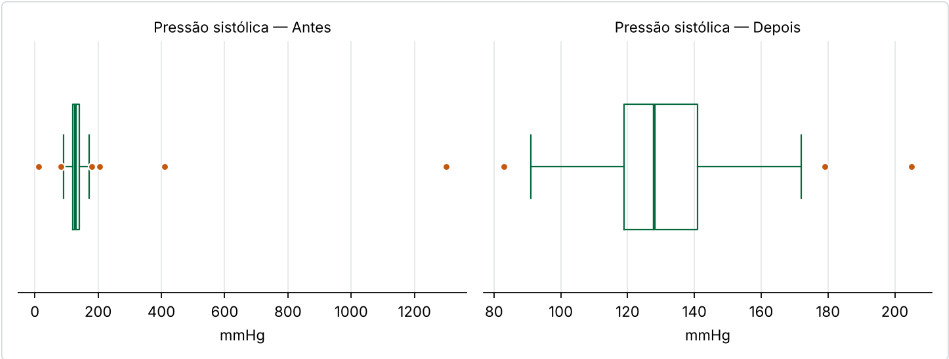

### Passo 8 - Ausentes

```
Ausentes após as correções: idade 10, peso 11, pressão 9, glicemia 27
Linhas com pelo menos um ausente: 50 de 240  ->  dropna() deixaria 190 linhas

Imputação: idade -> mediana; peso -> mediana por sexo;
           glicemia e pressão -> mediana por diagnóstico
Mediana da glicemia: Diabetes 169 | Hipertensão 96 | Rotina 98 | Inf. respiratória 99
Ausentes restantes: 0
```

### Passo 9 - Normalização e padronização

| | idade | idade_minmax | idade_z | glicemia | glicemia_minmax | glicemia_z |
|------|---------|----------------|-----------|------------|-------------------|--------------|
| mean | 53.17 | 0.50 | 0.00 | 108.98 | 0.34 | -0.00 |
| std | 20.05 | 0.28 | 1.00 | 28.72 | 0.21 | 1.00 |
| min | 18.00 | 0.00 | -1.75 | 62.00 | 0.00 | -1.64 |
| max | 89.00 | 1.00 | 1.79 | 202.00 | 1.00 | 3.24 |

### Passo 10 - Tidy data

```
Formato largo (5 x 5):  municipio | mar | abr | mai | jun
melt -> formato longo (20 x 3): municipio | mes | doses

Total de doses por mês: mar 967 | abr 2732 | mai 3100 | jun 1193
Mês de pico: Natal abr; Mossoró, Parnamirim, Caicó e Pau dos Ferros mai
```

### Passo 11 - Relatório de limpeza

```
linhas_originais       250
duplicatas_removidas   10
pressoes_impossiveis   3
idades_impossiveis     3
linhas_finais          240
ausentes_finais        0
```

### Parte III - Exercício prático

Para treinar - não precisa ser entregue

O exercício usa dados/triagem\_pa\_sujo.csv : 64 registros sintéticos de triagem em um pronto atendimento, com idade, temperatura, frequência cardíaca, saturação de O₂ e a classificação de risco (Azul, Verde, Amarelo, Vermelho). O notebook Aula09\_Exercicio\_Pratico.ipynb traz os oito passos com trechos TODO e, em cada um, o resultado esperado para você conferir.

| Passo | O que fazer | Para conferir |
|----------------------|-----------------------------------------------------------------------|-------------------------------------------------------------------------------|
| 1. Diagnóstico | shape , isna().sum() , duplicated().sum() | 64 × 7; 4 ausentes na temperatura e 2 na saturação; 4 duplicadas |
| 2. Duplicatas | drop_duplicates() | 60 linhas |
| 3. Categorias | str.strip().str.capitalize() na classificação de risco | Verde 30, Amarelo 21, Azul 7, Vermelho 2 |
| 4. Outliers (IQR) | limites de Q1 - 1,5·IQR e Q3 + 1,5·IQR | FC: 300; temperatura: 375; saturação: 9, 90 e 92 |
| 5. Regras de domínio | temperatura > 45 → ÷10; FC fora de 30-220 → NaN; saturação < 50 → NaN | ausentes: temperatura 4, FC 1, saturação 3 (90 e 92 são reais e ficam) |
| 6. Imputação | temperatura → mediana; saturação e FC → mediana por risco | mediana da temperatura 36,8 °C; saturação mediana do Vermelho 91%; 0 ausentes |
| 7. Escalas | fc_minmax e temp_z | fc_minmax de 0 a 1 (média 0,43); temp_z com média 0 e desvio 1 |
| 8. Conferência | médias por classificação de risco; salvar CSV limpo | Vermelho: 38,2 °C, 117 bpm, 91% de saturação |

### SINAL DE ALERTA

Se, no passo 8, alguma média de temperatura passar de 40 °C, o erro de 375 °C ficou para trás. Conferir se o resultado faz sentido clínico é a melhor validação de uma limpeza.


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha de limpeza com Pandas

| Tarefa | Código |
|---------------------|--------------------------------------------------------------|
| Ausentes por coluna | df.isna().sum() |
| Remover ausentes | df.dropna() · df.dropna(subset=["col"]) · df.dropna(axis=1) |
| Imputar | df["col"].fillna(df["col"].median()) |
| Imputar por grupo | df["col"].fillna(df.groupby("g")["col"].transform("median")) |
| Sentinela → ausente | df["col"].replace(999, np.nan) |
| Duplicatas | df.duplicated().sum() · df.drop_duplicates() |
| Texto | s.str.strip().str.title() · s.replace({...}) |
| Datas | pd.to_datetime(s, format="%d/%m/%Y", errors="coerce") |
| Corrigir linhas | df.loc[cond, "col"] = valor |
| IQR | q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1 |
| z-score | (s - s.mean()) / s.std() |
| Min-max | (s - s.min()) / (s.max() - s.min()) |
| Largo → longo | df.melt(id_vars="id", var_name="var", value_name="valor") |
| Longo → largo | df.pivot(index="id", columns="var", values="valor") |

### Apêndice B - Referências e leituras recomendadas

- WICKHAM, Hadley. Tidy Data. Journal of Statistical Software , v. 59, n. 10, 2014.
- McKINNEY, Wes. Python para Análise de Dados . 3. ed. São Paulo: Novatec, 2023. Cap. 7 (Limpeza e preparação dos dados).
- PANDAS. Working with missing data . pandas.pydata.org/docs/user\_guide/missing\_data.html
- PANDAS. Reshaping and pivot tables . pandas.pydata.org/docs/user\_guide/reshaping.html
- TUKEY, John W. Exploratory Data Analysis . Reading: Addison-Wesley, 1977.
- BRASIL. Lei nº 13.709/2018 - Lei Geral de Proteção de Dados Pessoais (LGPD) , art. 5º, II (dados sensíveis).

### O que vem na próxima aula

Laboratório: Pipeline de Limpeza Completo - a Aula 10 junta tudo em um pipeline ETL reprodutível, com transformação de tipos, engenharia de atributos (one-hot, label encoding, binning) e os escalonadores do scikit-learn, encerrando a Unidade 2.